In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import random
import struct
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "cnn-baseline"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), "device": str(DEVICE), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "torch")}}
display(pd.Series(environment, name="Environment"))

python          3.12.0
device             mps
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
torch           2.14.1
Name: Environment, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = torch.from_numpy(images[train_indices].astype(np.float32) / 255.0).unsqueeze(1)
X_validation = torch.from_numpy(images[validation_indices].astype(np.float32) / 255.0).unsqueeze(1)
y_train = labels[train_indices]
y_validation = labels[validation_indices]
train_dataset = TensorDataset(X_train, torch.from_numpy(y_train.astype(np.int64)))
validation_dataset = TensorDataset(X_validation, torch.from_numpy(y_validation.astype(np.int64)))
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=512, shuffle=False, num_workers=0)
assert tuple(X_train.shape) == (48000, 1, 28, 28)
assert tuple(X_validation.shape) == (12000, 1, 28, 28)
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "shape": [str(tuple(X_train.shape)), str(tuple(X_validation.shape))]}))

,split,shape
0,Training,"(48000, 1, 28, 28)"
1,Validation,"(12000, 1, 28, 28)"


In [3]:
def build_model():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Dropout(0.25), nn.Linear(64, 10),
    )

model = build_model().to(DEVICE)
criterion = nn.CrossEntropyLoss()
LEARNING_RATE = 0.001
MAX_EPOCHS = 15
PATIENCE = 3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {parameter_count:,}")

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Dropout(p=0.25, inplace=False)
  (10): Linear(in_features=64, out_features=10, bias=True)
)
Trainable parameters: 105,866


In [4]:
@torch.inference_mode()
def evaluate(network, loader):
    network.eval()
    total_loss = 0.0
    probabilities = []
    targets = []
    for inputs, target in loader:
        inputs, target = inputs.to(DEVICE), target.to(DEVICE)
        logits = network(inputs)
        loss = criterion(logits, target)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite evaluation loss")
        total_loss += loss.item() * len(target)
        probabilities.append(logits.softmax(dim=1).cpu().numpy())
        targets.append(target.cpu().numpy())
    probabilities = np.concatenate(probabilities)
    targets = np.concatenate(targets)
    return total_loss / len(targets), accuracy_score(targets, probabilities.argmax(axis=1)), probabilities

history = []
best_loss = float("inf")
best_epoch = None
stale_epochs = 0
checkpoint_path = RESULTS / "best-model.pt"
training_start = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    model.train()
    for inputs, target in train_loader:
        inputs, target = inputs.to(DEVICE), target.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(inputs), target)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss")
        loss.backward()
        optimizer.step()
    train_loss, train_accuracy, _ = evaluate(model, train_eval_loader)
    validation_loss, validation_accuracy, _ = evaluate(model, validation_loader)
    history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": validation_loss,
                    "train_accuracy": train_accuracy, "validation_accuracy": validation_accuracy,
                    "epoch_seconds": time.perf_counter() - epoch_start})
    if validation_loss < best_loss:
        best_loss, best_epoch, stale_epochs = validation_loss, epoch, 0
        torch.save({key: value.detach().cpu().clone() for key, value in model.state_dict().items()}, checkpoint_path)
    else:
        stale_epochs += 1
    pd.DataFrame(history).to_csv(RESULTS / "training-history.csv", index=False)
    print(f"Epoch {epoch:02d}: train accuracy={train_accuracy:.4f}, validation accuracy={validation_accuracy:.4f}, validation loss={validation_loss:.4f}, best epoch={best_epoch}")
    if stale_epochs >= PATIENCE:
        break
training_seconds = time.perf_counter() - training_start
model.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
print(f"Restored epoch {best_epoch}; completed {len(history)} epochs in {training_seconds:.1f} seconds")

Epoch 01: train accuracy=0.8292, validation accuracy=0.8254, validation loss=0.4767, best epoch=1


Epoch 02: train accuracy=0.8659, validation accuracy=0.8598, validation loss=0.3893, best epoch=2


Epoch 03: train accuracy=0.8770, validation accuracy=0.8678, validation loss=0.3610, best epoch=3


Epoch 04: train accuracy=0.8865, validation accuracy=0.8785, validation loss=0.3274, best epoch=4


Epoch 05: train accuracy=0.8928, validation accuracy=0.8808, validation loss=0.3222, best epoch=5


...

Epoch 11: train accuracy=0.9179, validation accuracy=0.9030, validation loss=0.2703, best epoch=11


Epoch 12: train accuracy=0.9182, validation accuracy=0.9035, validation loss=0.2700, best epoch=12


Epoch 13: train accuracy=0.9189, validation accuracy=0.8992, validation loss=0.2730, best epoch=12


Epoch 14: train accuracy=0.9270, validation accuracy=0.9070, validation loss=0.2567, best epoch=14


Epoch 15: train accuracy=0.9255, validation accuracy=0.9086, validation loss=0.2579, best epoch=14
Restored epoch 14; completed 15 epochs in 36.5 seconds


In [5]:
training_loss, training_accuracy, train_probabilities = evaluate(model, train_eval_loader)
validation_loss, validation_accuracy, validation_probabilities = evaluate(model, validation_loader)
validation_predictions = validation_probabilities.argmax(axis=1)
assert np.isfinite(validation_probabilities).all()
assert np.allclose(validation_probabilities.sum(axis=1), 1, atol=1e-6)
metrics = [
    {"split": "Training", "accuracy": training_accuracy, "macro_f1": f1_score(y_train, train_probabilities.argmax(axis=1), average="macro"), "loss": training_loss},
    {"split": "Validation", "accuracy": validation_accuracy, "macro_f1": f1_score(y_validation, validation_predictions, average="macro"), "loss": validation_loss},
]
metrics_table = pd.DataFrame(metrics).set_index("split")
display(metrics_table.round(4))
report = classification_report(y_validation, validation_predictions, labels=np.arange(10), target_names=CLASS_NAMES.tolist(), output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))

,accuracy,macro_f1,loss
split,,,
Training,0.927,0.9268,0.1976
Validation,0.907,0.9066,0.2567


,precision,recall,f1-score,support
T-shirt/top,0.8336,0.8600,0.8466,1200
Trouser,0.9801,0.9850,0.9825,1200
Pullover,0.8636,0.8650,0.8643,1200
Dress,0.9302,0.8992,0.9144,1200
Coat,0.8092,0.8692,0.8381,1200
Sandal,0.9800,0.9800,0.9800,1200
Shirt,0.7652,0.7033,0.7330,1200
Sneaker,0.9632,0.9608,0.9620,1200
Bag,0.9776,0.9800,0.9788,1200
Ankle boot,0.9659,0.9675,0.9667,1200


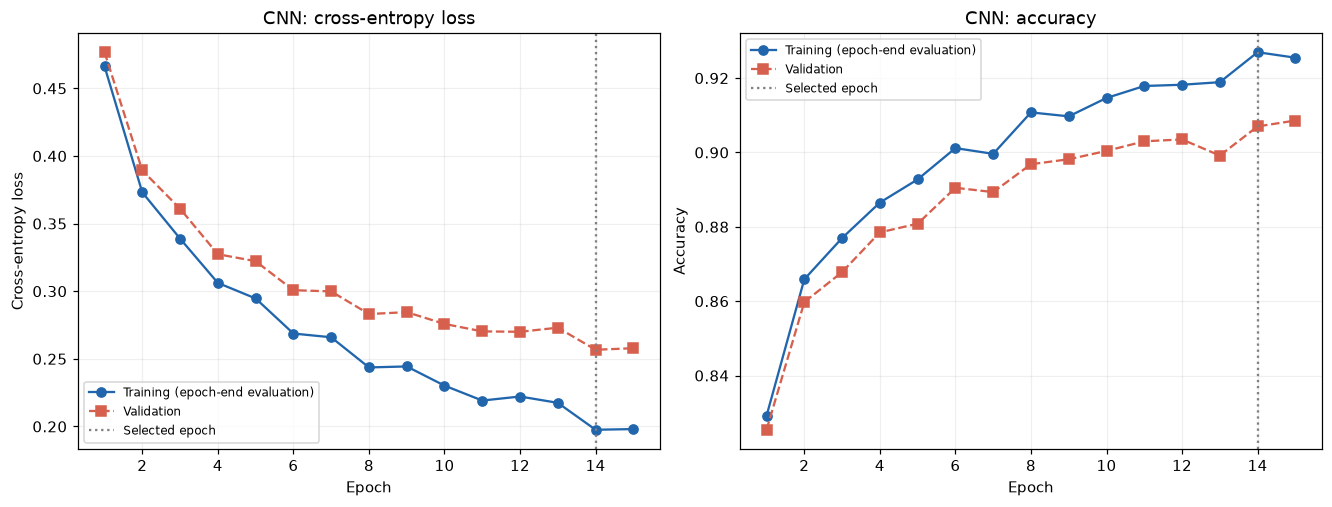

In [6]:
history_table = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Cross-entropy loss", "Accuracy"]):
    ax.plot(history_table.epoch, history_table[f"train_{metric}"], "o-", label="Training (epoch-end evaluation)", color="#2166ac")
    ax.plot(history_table.epoch, history_table[f"validation_{metric}"], "s--", label="Validation", color="#d6604d")
    ax.axvline(best_epoch, color="gray", linestyle=":", label="Selected epoch")
    ax.set(title=f"CNN: {title.lower()}", xlabel="Epoch", ylabel=title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.savefig(RESULTS / "learning-curves.png", bbox_inches="tight")
plt.show()

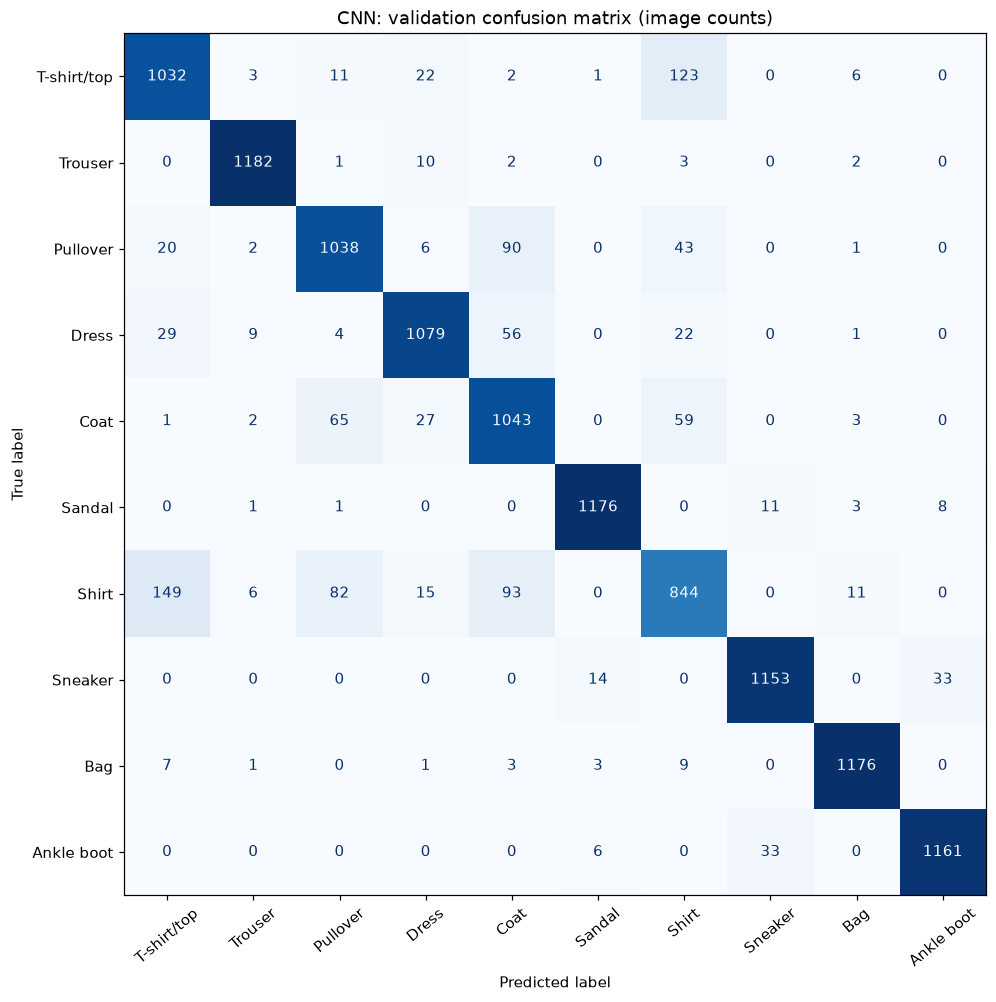

,actual,predicted,images,share_of_actual_class
0,Shirt,T-shirt/top,149,0.1242
1,T-shirt/top,Shirt,123,0.1025
2,Shirt,Coat,93,0.0775
3,Pullover,Coat,90,0.0750
4,Shirt,Pullover,82,0.0683
5,Coat,Pullover,65,0.0542
6,Coat,Shirt,59,0.0492
7,Dress,Coat,56,0.0467
8,Pullover,Shirt,43,0.0358
9,Sneaker,Ankle boot,33,0.0275


In [7]:
matrix = confusion_matrix(y_validation, validation_predictions, labels=np.arange(10))
assert matrix.sum() == len(y_validation)
assert np.isclose(np.trace(matrix) / matrix.sum(), metrics_table.loc["Validation", "accuracy"])
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=40, colorbar=False)
ax.set_title("CNN: validation confusion matrix (image counts)")
fig.savefig(RESULTS / "validation-confusion-matrix.png", bbox_inches="tight")
plt.show()
confusions = pd.DataFrame([
    {"actual": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "images": int(matrix[i,j]), "share_of_actual_class": float(matrix[i,j] / matrix[i].sum())}
    for i in range(10) for j in range(10) if i != j and matrix[i,j] > 0
]).sort_values("images", ascending=False).reset_index(drop=True)
display(confusions.head(10).round(4))

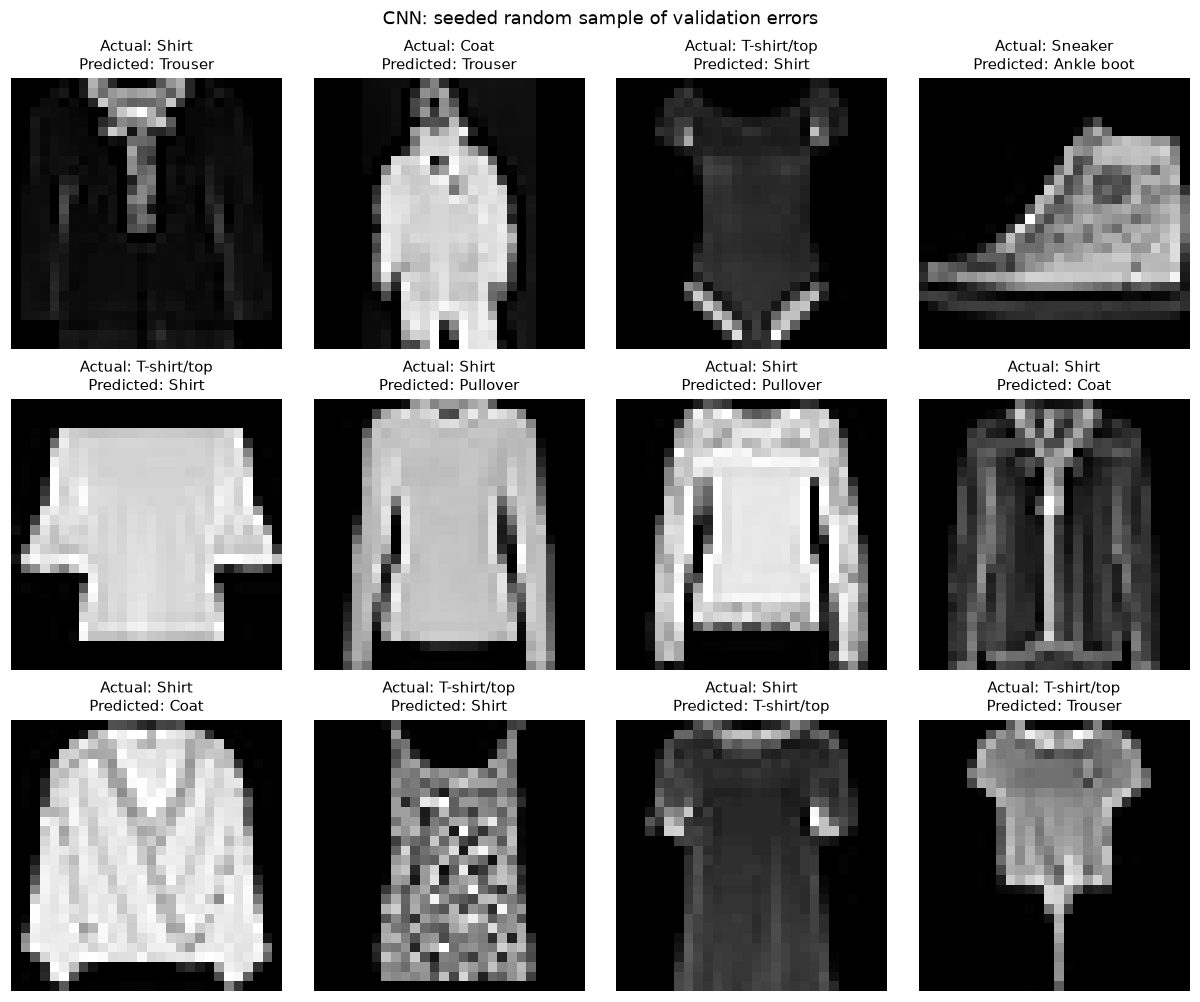

In [8]:
error_positions = np.flatnonzero(validation_predictions != y_validation)
rng = np.random.default_rng(SEED)
selected = rng.choice(error_positions, size=min(12, len(error_positions)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(11, 9), layout="constrained")
for ax in axes.ravel():
    ax.axis("off")
for ax, position in zip(axes.ravel(), selected):
    ax.imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Actual: {CLASS_NAMES[y_validation[position]]}\nPredicted: {CLASS_NAMES[validation_predictions[position]]}", fontsize=10)
fig.suptitle("CNN: seeded random sample of validation errors")
fig.savefig(RESULTS / "validation-errors.png", bbox_inches="tight")
plt.show()

In [9]:
model_rows = []
for folder in ["logistic-regression-regularization", "knn-comparison"]:
    path = ROOT / "results" / folder / "run-metadata.json"
    if path.exists():
        previous = json.loads(path.read_text())
        assert previous["split_sha256"] == split_sha256
        key = "C" if folder.startswith("logistic") else "k"
        selected = previous[f"selected_{key}"]
        row = next(r for r in previous["comparisons"] if r[key] == selected)
        model_rows.append({"model": f"{'Logistic regression' if key == 'C' else 'kNN'} ({key}={selected:g})", **{metric: row[metric] for metric in ["validation_accuracy", "validation_macro_f1", "shirt_recall"]}})
model_rows.append({"model": f"CNN (epoch {best_epoch})", "validation_accuracy": validation_accuracy,
                   "validation_macro_f1": metrics_table.loc["Validation", "macro_f1"], "shirt_recall": report["Shirt"]["recall"]})
model_comparison = pd.DataFrame(model_rows)
display(model_comparison.round(4))

,model,validation_accuracy,validation_macro_f1,shirt_recall
0,Logistic regression (C=0.1),0.8540,0.8530,0.5942
1,kNN (k=3),0.8538,0.8534,0.5892
2,CNN (epoch 14),0.9070,0.9066,0.7033


In [10]:
restored = build_model().to(DEVICE)
restored.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
_, _, restored_probabilities = evaluate(restored, validation_loader)
np.testing.assert_array_equal(restored_probabilities.argmax(axis=1), validation_predictions)
np.testing.assert_allclose(restored_probabilities, validation_probabilities, rtol=1e-5, atol=1e-6)
metrics_table.to_csv(RESULTS / "metrics.csv")
per_class.to_csv(RESULTS / "validation-classification-report.csv")
model_comparison.to_csv(RESULTS / "model-comparison.csv", index=False)
confusions.to_csv(RESULTS / "validation-confusions.csv", index=False)
pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RESULTS / "validation-confusion-matrix.csv")
pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": validation_predictions,
              "predicted_probability": validation_probabilities.max(axis=1)}).to_csv(RESULTS / "validation-predictions.csv", index=False)
metadata = {
    "model": "CNN", "architecture": str(model), "parameter_count": parameter_count,
    "environment": environment, "seed": SEED, "split_sha256": split_sha256, "source_files": training_files,
    "preprocessing": "float32 pixels / 255; channels first N x 1 x 28 x 28", "class_names": CLASS_NAMES.tolist(),
    "batch_size": BATCH_SIZE, "optimizer": "Adam", "learning_rate": LEARNING_RATE, "dropout": 0.25,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "selected_epoch": best_epoch, "epochs_run": len(history),
    "selection_rule": "Lowest validation cross-entropy loss", "training_seconds": training_seconds,
    "training_count": len(y_train), "validation_count": len(y_validation), "test_evaluated": False,
    "metrics": metrics, "model_comparison": model_rows,
    "checkpoint_sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/cnn-baseline artifacts")
print("Reloaded checkpoint reproduces all validation predictions and probabilities within tolerance")

Saved results/cnn-baseline artifacts
Reloaded checkpoint reproduces all validation predictions and probabilities within tolerance
